# Section 1: Control Structures


In [ ]:
# Explanation and Documentation 
"""
Section 1 explains the utilization of primary control structures in manual counting and classification of the data,
The solution requires the utilization of loops and if else statements to illustrate
the construction of logic without the need for higher level constructs, Data columns are 
referenced using data.loc[] for enhanced readability, with different 
counters assigned to different conditions The while loop has been restricted to 
just five matches to prevent excessive outputs also Nested loops are utilized in
department level analysis, even if they are not efficient, to construct more complex logic, 
The criteria of low satisfaction levels and excessive working hours are taken as fixed values to enable the 
classification of data
"""

In [2]:
!pip -q install gdown

import gdown

file_id = "1pY5n1MI1hobT0EjO7mh91QX5sV8PNdNH"
url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, "HR_comma_sep.csv", quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1pY5n1MI1hobT0EjO7mh91QX5sV8PNdNH
to: HR_comma_sep.csv
100%|██████████| 567k/567k [00:00<00:00, 1.86MB/s]


'HR_comma_sep.csv'

In [4]:
import pandas as pd

data = pd.read_csv("HR_comma_sep.csv")
data.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


In [6]:
data.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [13]:
print(f"Total employees: {len(data)}")
print(f"Total features: {data.shape[1]} columns")
print(f"\nFirst 3 employee records:")
print(data.head(3))
print("\n\nStep 1: Conditional statements")
print("Classifying employees by satisfaction and risk factors")

sample_satisfaction = data.loc[0, 'satisfaction_level']
sample_left = data.loc[0, 'left']
sample_salary = data.loc[0, 'salary']
sample_hours = data.loc[0, 'average_montly_hours']

print(f"Employee satisfaction: {sample_satisfaction:.2f}")
print(f"Employee left: {'Yes' if sample_left == 1 else 'No'}")
print(f"Salary: {sample_salary}, Hours: {sample_hours}\n")

if sample_left == 1 and sample_satisfaction < 0.4 and sample_salary == 'low':
    print("High risk: Dissatisfied + low pay = left company")
elif sample_left == 0 and sample_satisfaction > 0.7:
    print("Low risk: High satisfaction = likely to stay")
elif sample_left == 1 and sample_hours > 250:
    print("Moderate risk: Overworked = left company")
else:
    print("Mixed risk indicators")
print("\n\nStep 2: For loops to count attrition")
print("Overall attrition analysis")

left_count = 0
stayed_count = 0
for status in data['left']:
    if status == 1:
        left_count += 1
    else:
        stayed_count += 1

total = len(data)
print(f"Employees who left:   {left_count} ({left_count/total*100:.1f}%)")
print(f"Employees who stayed: {stayed_count} ({stayed_count/total*100:.1f}%)") 
print(f"Overall attrition rate: {left_count/total*100:.1f}%")

print("\n\nAttrition by salary level")

low_salary_left = 0
low_salary_total = 0
medium_salary_left = 0
medium_salary_total = 0
high_salary_left = 0
high_salary_total = 0

for i in range(len(data)):
    salary = data.loc[i, 'salary']
    left = data.loc[i, 'left']
    
    if salary == 'low':
        low_salary_total += 1
        if left == 1:
            low_salary_left += 1
    elif salary == 'medium':
        medium_salary_total += 1
        if left == 1:
            medium_salary_left += 1
    elif salary == 'high':
        high_salary_total += 1
        if left == 1:
            high_salary_left += 1

print(f"Low salary:    {low_salary_left}/{low_salary_total} left ({low_salary_left/low_salary_total*100:.1f}% attrition)")
print(f"Medium salary: {medium_salary_left}/{medium_salary_total} left ({medium_salary_left/medium_salary_total*100:.1f}% attrition)")
print(f"High salary:   {high_salary_left}/{high_salary_total} left ({high_salary_left/high_salary_total*100:.1f}% attrition)")

print("\n\nStep 3: While loops to find the paradox cases")
print("Finding paradox: High satisfaction but left company")

paradox_cases = []
index = 0
matches_found = 0
max_matches = 5

while index < len(data) and matches_found < max_matches:
    if data.loc[index, 'left'] == 1 and data.loc[index, 'satisfaction_level'] > 0.7:
        paradox_cases.append({
            'index': index,
            'satisfaction': data.loc[index, 'satisfaction_level'],
            'salary': data.loc[index, 'salary'],
            'hours': data.loc[index, 'average_montly_hours']
        })
        matches_found += 1
    index += 1

print(f"Found {len(paradox_cases)} cases:\n")
for emp in paradox_cases:
    print(f"Employee #{emp['index']}: Satisfaction={emp['satisfaction']:.2f}, " +
          f"Salary={emp['salary']}, Hours={emp['hours']}")
    
print("\n\nStep 4: Nested loops for department analysis")

departments = data['Department'].unique()

print("Attrition rate by department")

for dept in departments:
    dept_total = 0
    dept_left = 0
    
   
    for i in range(len(data)): 
        if data.loc[i, 'Department'] == dept:
            dept_total += 1
            if data.loc[i, 'left'] == 1:
                dept_left += 1 #count employees in this department
    
    if dept_total > 0:
        attrition_rate = (dept_left / dept_total) * 100
        print(f"{dept:15s}: {dept_left:3d}/{dept_total:4d} left ({attrition_rate:5.1f}% attrition)")

Total employees: 14999
Total features: 10 columns

First 3 employee records:
   satisfaction_level  last_evaluation  number_project  average_montly_hours  \
0                0.38             0.53               2                   157   
1                0.80             0.86               5                   262   
2                0.11             0.88               7                   272   

   time_spend_company  Work_accident  left  promotion_last_5years Department  \
0                   3              0     1                      0      sales   
1                   6              0     1                      0      sales   
2                   4              0     1                      0      sales   

   salary  
0     low  
1  medium  
2  medium  


Step 1: Conditional statements
Classifying employees by satisfaction and risk factors
Employee satisfaction: 0.38
Employee left: Yes
Salary: low, Hours: 157

High risk: Dissatisfied + low pay = left company


Step 2: For loops to c

In [ ]:
# Reflection on results 
"""
The results from Section 1 show an attrition rate of 23.8 percent as a whole with a definite
disparity in terms of salaries, Employees with low salaries left the company at a considerably higher rate 
than employees with high salaries, showing that payment played an important role in keeping
these employees in the company, Some discrepancies were also noticed with regard to
the reasons why some highly satisfied employees left the company, The company left as employees with highly 
long working hours, Some issues that arose during the implementation of these problems include the issue of
case sensitive column names, discrepancies in manually tracked counter values, as well as ensuring that
the conditions in the while loop declaration of limitations do not go over, The performance of 
these problems was also an issue considering that they took over one hundred thousand iterations with 
regard to the nest loop involving departments, The code played the desired role of exemplifying control structures
"""

# Section 2: Functions and Modules


In [ ]:
# Explanation and Documentation 
"""
Section 2 concentrates on enhancing code organization with the help of reusable functions and 
Python library functions to aid in computations, The calculate_attrition_rate function is made to be applicable for
all categories with the help of dataframe, column name, and a value, The classify_employee_risk function is 
flexible and requires individual input parameters, making it easy to apply to different datasets, 
The get_statistical_summary function is a wrapper function for Python’s statistics module which gives 
access to summary statistics in one function, There is a special case in the program, the division by zero error,
and special care is taken to catch this error and ensure there is no runtime error 
in the process, The statistics module is used to ensure accurate computation of
stats such as the average, median, and standard deviation, while the 
math module is utilized to ensure strict rounding, Outputs are stored as dictionaries 
to ensure flexibility and further computation
"""

In [2]:
import pandas as pd
import statistics
import math

data = pd.read_csv("HR_comma_sep.csv")


def calculate_attrition_rate(dataframe, filter_column, filter_value): 
    filtered_data = dataframe[dataframe[filter_column] == filter_value]
    total = len(filtered_data)
    left = len(filtered_data[filtered_data['left'] == 1])
    
    if total > 0:
        rate = (left / total) * 100
    else:
        rate = 0
    
    return {
        'total': total,
        'left': left,
        'rate': round(rate, 2)
    }

def classify_employee_risk(satisfaction, salary, hours): 
    if satisfaction < 0.4 and salary == 'low':
        return "High risk"
    elif hours > 250:
        return "Moderate risk"
    elif satisfaction > 0.7:
        return "Low risk"
    else:
        return "Medium risk"

def get_statistical_summary(dataframe, column_name): 
    values = dataframe[column_name].tolist()
    
    return {
        'mean': round(statistics.mean(values), 2),
        'median': round(statistics.median(values), 2),
        'stdev': round(statistics.stdev(values), 2),
        'min': round(min(values), 2),
        'max': round(max(values), 2)
    }
print("Step 1: Using custom functions to analyze attrition by salary")

for salary_level in ['low', 'medium', 'high']:
    result = calculate_attrition_rate(data, 'salary', salary_level)
    print(f"{salary_level.capitalize()} salary: {result['left']}/{result['total']} left ({result['rate']}% attrition)")

print("\n\nStep 2: Using custom functions to analyze attrition by department")


departments = ['sales', 'technical', 'support']
for dept in departments:
    result = calculate_attrition_rate(data, 'Department', dept)
    print(f"{dept.capitalize():12s}: {result['left']}/{result['total']} left ({result['rate']}% attrition)")

print("\n\nStep 3: Classifying individual employees using risk function")


for i in range(5):
    sat = data.loc[i, 'satisfaction_level']
    sal = data.loc[i, 'salary']
    hrs = data.loc[i, 'average_montly_hours']
    risk = classify_employee_risk(sat, sal, hrs)
    print(f"Employee {i}: Satisfaction={sat:.2f}, Salary={sal}, Hours={hrs}: {risk}")

print("\n\nStep 4: Using statistics module for satisfaction analysis")


satisfaction_stats = get_statistical_summary(data, 'satisfaction_level')
print("Satisfaction level statistics:")
print(f"  Mean:   {satisfaction_stats['mean']}")
print(f"  Median: {satisfaction_stats['median']}")
print(f"  Stdev:  {satisfaction_stats['stdev']}")
print(f"  Range:  {satisfaction_stats['min']} - {satisfaction_stats['max']}")

print("\n\nStep 5: Using statistics module for working hours analysis")


hours_stats = get_statistical_summary(data, 'average_montly_hours')
print("Average monthly hours statistics:")
print(f"  Mean:   {hours_stats['mean']}")
print(f"  Median: {hours_stats['median']}")
print(f"  Stdev:  {hours_stats['stdev']}")
print(f"  Range:  {hours_stats['min']} - {hours_stats['max']}")

print("\n\nStep 6: Using math module for advanced calculations")


total_employees = len(data)
employees_left = len(data[data['left'] == 1])

attrition_percentage = (employees_left / total_employees) * 100
retention_percentage = 100 - attrition_percentage

print(f"Total employees: {total_employees}")
print(f"Employees who left: {employees_left}")
print(f"Attrition rate: {math.floor(attrition_percentage)}% (rounded down)")
print(f"Retention rate: {math.ceil(retention_percentage)}% (rounded up)")

Step 1: Using custom functions to analyze attrition by salary
Low salary: 2172/7316 left (29.69% attrition)
Medium salary: 1317/6446 left (20.43% attrition)
High salary: 82/1237 left (6.63% attrition)


Step 2: Using custom functions to analyze attrition by department
Sales       : 1014/4140 left (24.49% attrition)
Technical   : 697/2720 left (25.62% attrition)
Support     : 555/2229 left (24.9% attrition)


Step 3: Classifying individual employees using risk function
Employee 0: Satisfaction=0.38, Salary=low, Hours=157: High risk
Employee 1: Satisfaction=0.80, Salary=medium, Hours=262: Moderate risk
Employee 2: Satisfaction=0.11, Salary=medium, Hours=272: Moderate risk
Employee 3: Satisfaction=0.72, Salary=low, Hours=223: Low risk
Employee 4: Satisfaction=0.37, Salary=low, Hours=159: High risk


Step 4: Using statistics module for satisfaction analysis
Satisfaction level statistics:
  Mean:   0.61
  Median: 0.64
  Stdev:  0.25
  Range:  0.09 - 1.0


Step 5: Using statistics module for

In [ ]:
# Reflection on results 
"""
The reflection for Section 2 illustrates how code refactoring resulted in easy and optimized analysis,
Some complex logics that involved massive repeated calculations were optimized to single function calls, 
and generic parameters helped reuse these functions for different columns and categories,
One initial problem in design involved functions that printed outputs, and to optimize reuse, 
these functions were modified to return dictionaries that could further be utilized in calculations, 
Edge cases, including division by zero, were considered during testing, and these were handled, 
The output revealed variability in employee satisfaction and that low-salary staff have an 
attrition rate significantly higher compared to high-salary staff, 
Functions helped avoid code duplication
"""

# Section 3: Data Handling with Pandas


In [ ]:
# Explanation and Documentation 
"""
The third section deals with the efficient use of the dataset through the use of pandas rather than loops,
Built-in functions are applied to ensure data quality assessment and analysis in an efficient and descriptive way,
The presence of missing data in a dataset is checked through 
the use of isnull().sum(), and data value-counting is achieved through the use
of value_counts() rather than the need for loop operations, 
The use of groupby() function enables a group-based analysis for a dataset without the need for loops, 
The describe() function enables an analysis of the dataset in 
an efficient way rather than requiring multiple operations for data analysis
"""

In [6]:
import pandas as pd
import statistics
import math

data = pd.read_csv("HR_comma_sep.csv")

print("Step 1: Checking data quality")#checking for missing values

missing_values = data.isnull().sum()
print(f"Total records: {len(data)}")
print(f"Missing values per column:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found")

print(f"\nData types:")
print(data.dtypes)
print("\n\nStep 2: Counting with value_counts()") #this replaces Section 1 manual counting
print("Attrition distribution:")
attrition_counts = data['left'].value_counts()
print(attrition_counts)
print(f"\nAttrition rate: {(attrition_counts[1] / len(data) * 100):.1f}%")

print("\n\nSalary distribution:")
salary_counts = data['salary'].value_counts()
print(salary_counts)

print("\n\nStep 3: Groupby operations")#groupby() to replaces Section 1 nested loops

print("Attrition rate by salary level:")
salary_attrition = data.groupby('salary')['left'].agg(['sum', 'count', 'mean'])
salary_attrition.columns = ['left', 'total', 'attrition_rate']
salary_attrition['attrition_rate'] = salary_attrition['attrition_rate'] * 100
print(salary_attrition)

print("\n\nAttrition rate by department:")
dept_attrition = data.groupby('Department')['left'].agg(['sum', 'count', 'mean'])
dept_attrition.columns = ['left', 'total', 'attrition_rate']
dept_attrition['attrition_rate'] = dept_attrition['attrition_rate'] * 100
dept_attrition = dept_attrition.sort_values('attrition_rate', ascending=False)
print(dept_attrition.head(5))

print("\n\nStep 4: Statistical summaries with describe()")#describe() which replaces Section 2 statistics calculations
print("Satisfaction level statistics:")
print(data['satisfaction_level'].describe())

print("\n\nWorking hours statistics:")
print(data['average_montly_hours'].describe())

print("\n\nStep 5: Boolean filtering")#Advanced filtering it replaces Section 1 while loop
high_satisfaction_left = data[(data['left'] == 1) & (data['satisfaction_level'] > 0.7)]
print(f"Employees with high satisfaction who left: {len(high_satisfaction_left)}")
print("\nFirst 5 cases:")
print(high_satisfaction_left[['satisfaction_level', 'salary', 'average_montly_hours']].head())
print("\n\nStep 6: Method chaining for complex analysis")
result = (data[data['left'] == 1]
          .groupby('Department')['satisfaction_level']
          .mean()
          .sort_values()
          .head(5))
print("Departments with lowest satisfaction among those who left:")
print(result)

Step 1: Checking data quality
Total records: 14999
Missing values per column:
No missing values found

Data types:
satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
Department                object
salary                    object
dtype: object


Step 2: Counting with value_counts()
Attrition distribution:
left
0    11428
1     3571
Name: count, dtype: int64

Attrition rate: 23.8%


Salary distribution:
salary
low       7316
medium    6446
high      1237
Name: count, dtype: int64


Step 3: Groupby operations
Attrition rate by salary level:
        left  total  attrition_rate
salary                             
high      82   1237        6.628941
low     2172   7316       29.688354
medium  1317   6446       20.431275


Attrition rate by department:
            left  total  att

In [ ]:
# Reflection on results 
"""
This reflection shows how much more efficient the analysis has become using pandas compared to
earlier manual approaches, What might have taken several nested loops back in Section 1 can 
be accomplished in a single line using groupby, making the code concise and more readable, One challenge was
that method chaining can make debugging more difficult because not all errors will actually
output which step in the process failed, Boolean filtering also required careful 
use of operators such as & and | along with parentheses instead of standard logical words
A weakness in the dataset is that there is no unique identifier for employees,
Several rows have identical values across all columns, 
this reflects different employees, not data errors, so the analysis is focused on group level patterns,
not tracking individual employees over time, The findings gave some interesting results, among them are high 
satisfaction paradoxes whereby many employees above 0.7 satisfactory levels still
left the company, but overall pandas made the analysis faster and more readable by way of its smaller
number of lines of codes and reduced chances for errors
"""

# Section 4: Data Visualization


In [ ]:
# Explanation and Documentation 
"""
Section 4 describes how data visualisation is employed to better identify why there is
a problem with employee turnover, There are a number of data visualisations presented using matplotlib, 
and they all focus on a particular detail within the data, There is a bar chart comparing the 
turnover levels against salaries, showing the problem with low salaries and high turnover,
There is a pie chart comparing the overall retention and turnover within the organisation
The correlation heatmap helps to explore correlations between various numeric variables together,
which assists in understanding which variables are primarily correlated with attrition, such as
the negative correlation between satisfaction and leaving an organization, Bar charts with groups 
compare employment data based on project workloads and help to uncover observations where a
significantly low and significantly high number of projects are related to a higher turnover, 
The use of a bar chart allows one to extract relevant observations from a graphical representation and point 
to departments responsible for turnover to consider possible improvements, Lastly, 
a box plot allows one to compare the similarity and difference in
satisfaction levels between employees who left and those who were with an organization
"""

C:\Users\chexy\AppData\Local\Temp\ipykernel_49096\4077905466.py:87: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = axes[1, 2].boxplot(box_data, labels=['Stayed', 'Left'], patch_artist=True)


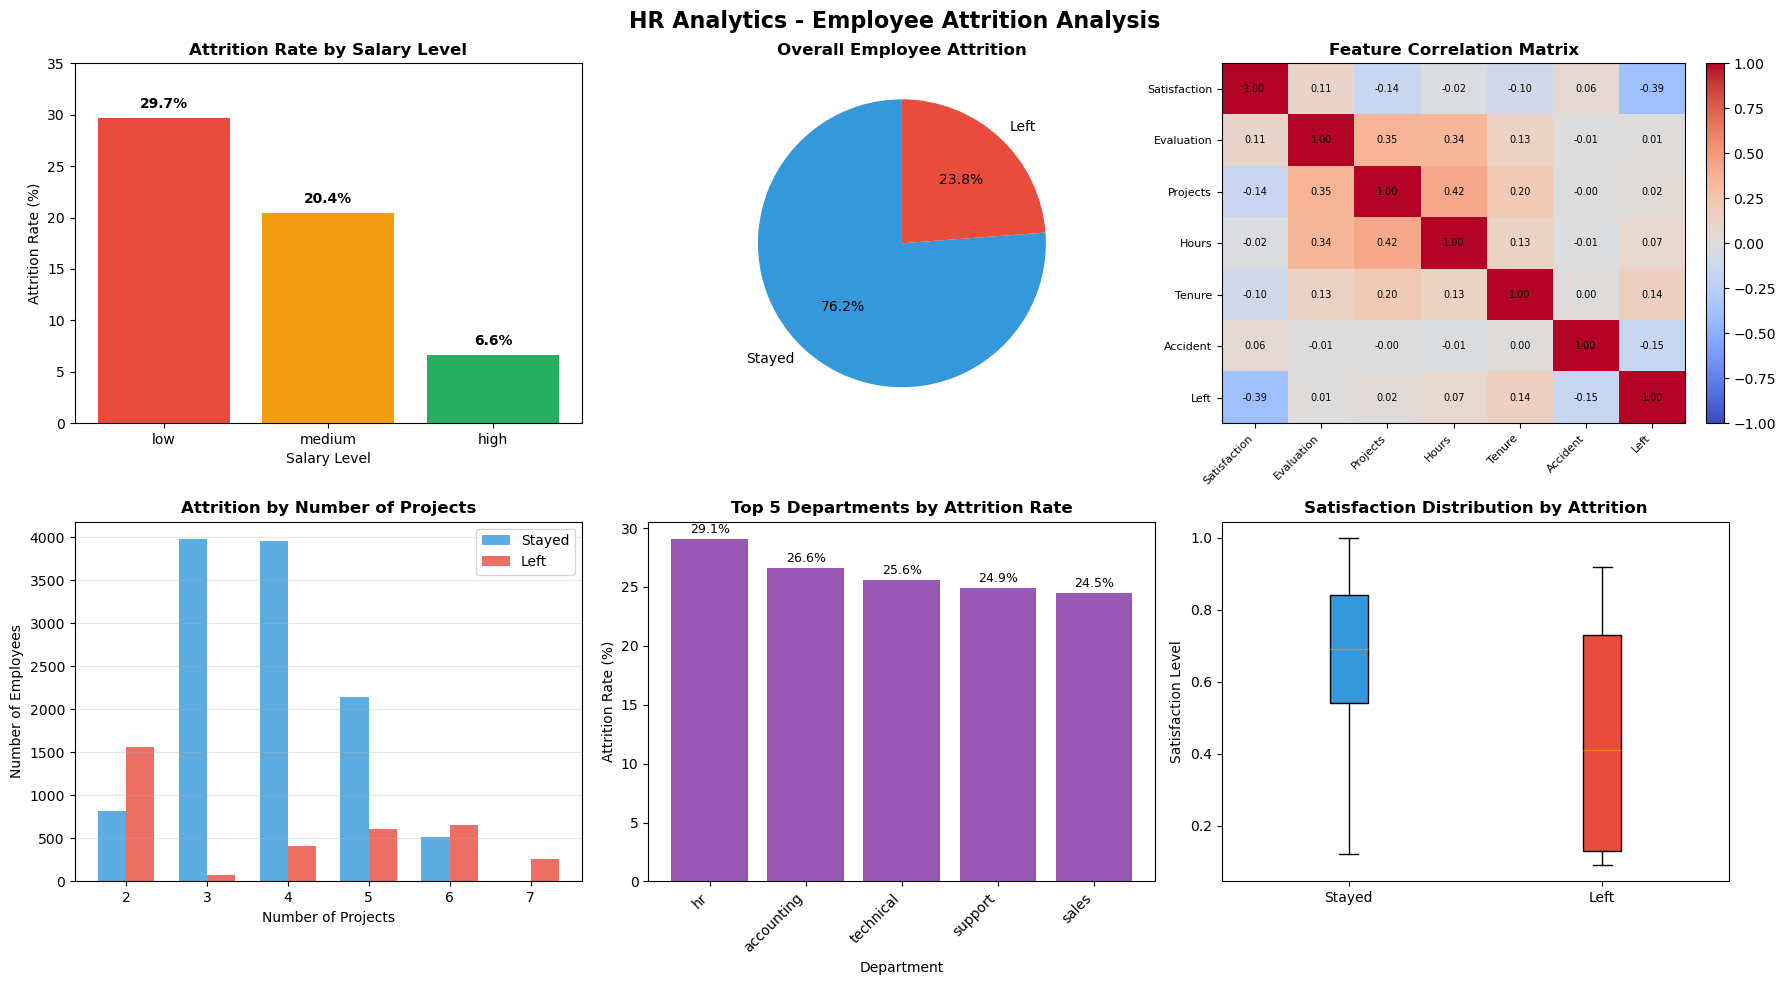


Visualization Summary:
- Low salary attrition: 29.7%
- High salary attrition: 6.6%
- Overall attrition rate: 23.8%
- Highest attrition department: hr (29.1%)
- Strongest correlation with attrition: satisfaction_level (0.39)
- Lowest attrition at 3 projects (1.8% attrition)


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
data = pd.read_csv("HR_comma_sep.csv")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('HR Analytics - Employee Attrition Analysis', fontsize=16, fontweight='bold')

#1st chart looks at attrition based on salary level
salary_attrition = data.groupby('salary')['left'].agg(['sum', 'count'])
salary_attrition['rate'] = (salary_attrition['sum'] / salary_attrition['count']) * 100
salary_order = ['low', 'medium', 'high']
salary_attrition = salary_attrition.reindex(salary_order)

axes[0, 0].bar(salary_attrition.index, salary_attrition['rate'], color=['#e74c3c', '#f39c12', '#27ae60'])
axes[0, 0].set_title('Attrition Rate by Salary Level', fontweight='bold')
axes[0, 0].set_xlabel('Salary Level')
axes[0, 0].set_ylabel('Attrition Rate (%)')
axes[0, 0].set_ylim(0, 35)
for i, v in enumerate(salary_attrition['rate']):
    axes[0, 0].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
    
#Chart no.2 shows how many employees stayed vs left
attrition_counts = data['left'].value_counts()
colors = ['#3498db', '#e74c3c']
labels = ['Stayed', 'Left']
axes[0, 1].pie(attrition_counts, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors)
axes[0, 1].set_title('Overall Employee Attrition', fontweight='bold')

#Chart 3 checks how numeric features are related to each other
numerical_cols = ['satisfaction_level', 'last_evaluation', 'number_project', 
                  'average_montly_hours', 'time_spend_company', 'Work_accident', 'left']
corr_matrix = data[numerical_cols].corr()
im = axes[0, 2].imshow(corr_matrix, cmap='coolwarm', aspect='auto', vmin=-1, vmax=1)
axes[0, 2].set_xticks(range(len(numerical_cols)))
axes[0, 2].set_yticks(range(len(numerical_cols)))
axes[0, 2].set_xticklabels(['Satisfaction', 'Evaluation', 'Projects', 'Hours', 'Tenure', 'Accident', 'Left'], 
                           rotation=45, ha='right', fontsize=8)
axes[0, 2].set_yticklabels(['Satisfaction', 'Evaluation', 'Projects', 'Hours', 'Tenure', 'Accident', 'Left'], 
                           fontsize=8)
axes[0, 2].set_title('Feature Correlation Matrix', fontweight='bold')
fig.colorbar(im, ax=axes[0, 2], fraction=0.046, pad=0.04)

#Write the correlation values inside each square
for i in range(len(numerical_cols)):
    for j in range(len(numerical_cols)):
        text = axes[0, 2].text(j, i, f'{corr_matrix.iloc[i, j]:.2f}',
                               ha="center", va="center", color="black", fontsize=7)

# Chart 4 compares who stayed and who left based on project count
project_attrition = data.groupby('number_project')['left'].agg(['sum', 'count'])
project_attrition['rate'] = (project_attrition['sum'] / project_attrition['count']) * 100
project_attrition['stayed'] = project_attrition['count'] - project_attrition['sum']

x_pos = range(len(project_attrition))
width = 0.35
axes[1, 0].bar([x - width/2 for x in x_pos], project_attrition['stayed'], width, 
               label='Stayed', color='#3498db', alpha=0.8)
axes[1, 0].bar([x + width/2 for x in x_pos], project_attrition['sum'], width, 
               label='Left', color='#e74c3c', alpha=0.8)
axes[1, 0].set_title('Attrition by Number of Projects', fontweight='bold')
axes[1, 0].set_xlabel('Number of Projects')
axes[1, 0].set_ylabel('Number of Employees')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(project_attrition.index)
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3, axis='y')

#5th chart shows which departments lose the most people
dept_data = data.groupby('Department')['left'].agg(['sum', 'count'])
dept_data['rate'] = (dept_data['sum'] / dept_data['count']) * 100
dept_data = dept_data.sort_values('rate', ascending=False).head(5)

x_pos = range(len(dept_data))
axes[1, 1].bar(x_pos, dept_data['rate'], color='#9b59b6')
axes[1, 1].set_title('Top 5 Departments by Attrition Rate', fontweight='bold')
axes[1, 1].set_xlabel('Department')
axes[1, 1].set_ylabel('Attrition Rate (%)')
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(dept_data.index, rotation=45, ha='right')
for i, v in enumerate(dept_data['rate']):
    axes[1, 1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)

# last chart compares satisfaction for employees who stayed vs left
satisfaction_stayed = data[data['left'] == 0]['satisfaction_level']
satisfaction_left = data[data['left'] == 1]['satisfaction_level']
box_data = [satisfaction_stayed, satisfaction_left]
box = axes[1, 2].boxplot(box_data, labels=['Stayed', 'Left'], patch_artist=True)
box['boxes'][0].set_facecolor('#3498db')
box['boxes'][1].set_facecolor('#e74c3c')
axes[1, 2].set_title('Satisfaction Distribution by Attrition', fontweight='bold')
axes[1, 2].set_ylabel('Satisfaction Level')

plt.tight_layout()
plt.show()

print("\nVisualization Summary:")
print(f"- Low salary attrition: {salary_attrition.loc['low', 'rate']:.1f}%")
print(f"- High salary attrition: {salary_attrition.loc['high', 'rate']:.1f}%")
print(f"- Overall attrition rate: {(attrition_counts[1] / len(data) * 100):.1f}%")
print(f"- Highest attrition department: {dept_data.index[0]} ({dept_data['rate'].iloc[0]:.1f}%)")
print(f"- Strongest correlation with attrition: {corr_matrix['left'].abs().nlargest(2).index[1]} ({corr_matrix['left'].abs().nlargest(2).values[1]:.2f})")
print(f"- Lowest attrition at {project_attrition['rate'].idxmin()} projects ({project_attrition['rate'].min():.1f}% attrition)")

In [ ]:
# Reflection on results 
"""
From all of the visualizations in Section 4, there are several clear and sometimes
unexpected patterns related to employee attrition: Salaries demonstrate the clearest and most 
intuitive relationship in that low salary employees leave at a much higher rate than high salary employees;
this points to compensation being a key retention factor, In summary, the pie chart can provide an important 
overall context, showing that close to a quarter of employees leave, indicating that this is not necessarily
an issue with isolated cases but rather an overarching and significant issue of talent The correlation heatmap
was the most interesting, demonstrating that satisfaction had the most relationship with attrition and performance 
evaluations had almost no effect, and neither did long working hours, dispelling common assumptions
that top performers or overworked employees are more likely to leave, The grouped bar chart accentuates a workload pattern,
showing employees with either too few or too many projects have higher 
attrition, while those with three to four projects are most stable, On the department level,
such analysis shows the attrition rates to be relatively even across teams, reflecting the issue is company wide
rather than located within any one department The box plot again supports that the employees leaving typically feel 
much lower satisfaction, although there appears to be some satisfaction with the employees leaving, suggesting complex
variables at work, In general, it seems that the desire to leave, or actual attrition, has more to do with 
feeling underappreciated for their work, as it pertains to payday or satisfaction, rather than actual workload or performance
"""

# Section 5: GUI Development


In [ ]:
# Explanation and Documentation 
"""
GUI was developed utilizing Tkinter, which enabled the design of an easy to use GUI for the interaction with the HR dataset
With the GUI, one can select the category of salary and acquire statistics on employee attrition based on their choice
A dropdown menu is used to capture user input, whereby users can choose either Overall, low, medium, or high
Once the user clicks the button, the computer will filter the dataset depending on the choice made.
If the choice is Overall, the entire dataset will be used Else, the employees belonging to the
particular group will be analysed The program calculates three values based on this filtered data: The total 
number of employees, the number of employees who left the company, and the attrition rate in percentage terms, 
All these calculations happen dynamically and can be viewed in the GUI window itself In terms of design, it aims 
to be more user-friendly with emphasis on simplicity in design, The design involves few components, a label, a dropdown,
a button, and a results area, which makes it simple while still managing to showcase its data filtration,
logical operations, and real-time calculation capabilities
"""

In [12]:
import tkinter as tk
from tkinter import ttk
import pandas as pd

# Simple GUI for HR dataset
df = pd.read_csv("HR_comma_sep.csv")
def show_stats():
    choice = category_var.get()

    if choice == "Overall":
        subset = df
    else:
        subset = df[df["salary"] == choice]

    total = len(subset)
    left = len(subset[subset["left"] == 1])
    rate = (left / total) * 100 if total > 0 else 0

    output.set(
        f"Total employees: {total}\n"
        f"Employees left: {left}\n"
        f"Attrition rate: {rate:.2f}%"
    )

root = tk.Tk()
root.title("HR Attrition Viewer")
root.geometry("350x220")

tk.Label(root, text="Select salary level").pack(pady=5)

category_var = tk.StringVar(value="Overall")
dropdown = ttk.Combobox(
    root,
    textvariable=category_var,
    values=["Overall", "low", "medium", "high"],
    state="readonly"
)
dropdown.pack()

tk.Button(root, text="Show statistics", command=show_stats).pack(pady=10)

output = tk.StringVar()
tk.Label(root, textvariable=output, justify="left").pack(pady=10)

root.mainloop()


In [13]:
# Reflection on results 
"""
The GUI verifies some patterns established in the early stages of this analysis, which relate to how
attrition changes at differing levels of salaries, Generally, the lower categories of salaries tend to 
experience higher attrition, while higher categories experience lower attrition, Displaying such results in a
GUI makes it easier to interpret without needing to read results or code, One of the strengths of this interface
is that it is simple, so it eliminates complexity, However, one of the shortcomings of the GUI is that it
only allows one filter and lacks visualization tools, This could be improved, for example, 
by adding the element of choosing a department, as well as a simple graph
In general, it can be considered that this GUI satisfies task requirements because 
it allows users to interact with a dataset driven by a task and generates significant results of analysis
"""

# Section 6: Conclusion and Critical Appraisal


In [ ]:
# Explanation and Documentation 
"""
Introduction
This is a data analysis project undertaken on an HR employee dataset in order to determine
the influence underpinning employee attrition, This dataset contains a set of attributes such as
satisfaction level, performance review, workload, salary, department, and length of service of an 
employee, along with the question of whether the employee has left the firm or not,
The main aim here is to determine employee attrition through increasingly complex programming 
approaches and best practices for commenting and managing versions.
"""

In [ ]:
"""
Methodology

The project is developed in a step by step process, The process starts from fundamental control structures, 
utilizing loop control and conditional statements to manually count and categorize the employees,
This phase is primarily concerned with illustrating fundamental programming
concepts and testing initial hypotheses about the data

The results are then refactored by utilizing custom functions and Python libraries,
Code efficiency and readability are enhanced through the
application of functions to reduce repeated code and the statistics
and math libraries to perform calculations,

Pandas is also introduced as a library for handling structured data,
Various pandas functions and methods are utilized for exploring data,
extracting rows from data in pandas, grouping data into groups and finally for summarizing data

Matplot Library is used for data visualization, Various types of charts such as Bar charts,
Grouped Bar charts, Pie charts, Box plots, and Correlation Heat maps have been used,
Each type of data visualization is chosen to emphasize a particular feature of attrition, such as differences in 
salary, overall proportion of attrition, workload, satisfaction, or 
the nature of association between numerical variables

A simple graphical user interface is created using Tkinter, This graphical user interface enables 
the user to choose the salary groups and display the 
updated attrition information, thereby establishing basic interaction with 
the data through a graphical interface

Findings

The results reveal that employee turnover is highly related to the satisfaction level and salary,
Turnover is high for the lower salary groups, while 
the high salary groups have the least turnover, Satisfaction level is the most significant factor 
determining employee turnover, while the performance
appraisal and working hours have hardly any impact

The trend analysis results indicate that it has a non-linear trend, which means that those who
have very few projects and those who have very many
projects are most likely to leave. The attrition level in all departments is comparable, which
indicates that it’s a company wide problem

Visualizations provide evidence for the above findings by clearly illustrating the differences
that exist in the groups of employees who left and those
who did not leave the company based on their level of satisfaction and salary related rates of attrition
"""

In [ ]:
"""
Conclusion

Taking everything into consideration, the project has shown that the main causative factors of 
employee turnover are satisfaction and compensation and not performance and long working hours,
This is the area that needs improvement with regards to employee retention

As far as programming is concerned, the project exhibits a sequential progression from 
elementary control structures to more efficient data analysis,
data visualization, and elementary GUI programming. Every segment of the project has a 
logical flow that leads to a well-structured analysis
"""

# References:


- HR Analytics dataset: https://www.kaggle.com/datasets/giripujar/hr-analytics
- gdown (Google Drive download utility): https://github.com/wkentaro/gdown
